#### 10/11/2026

# SIS Gravitational Lens

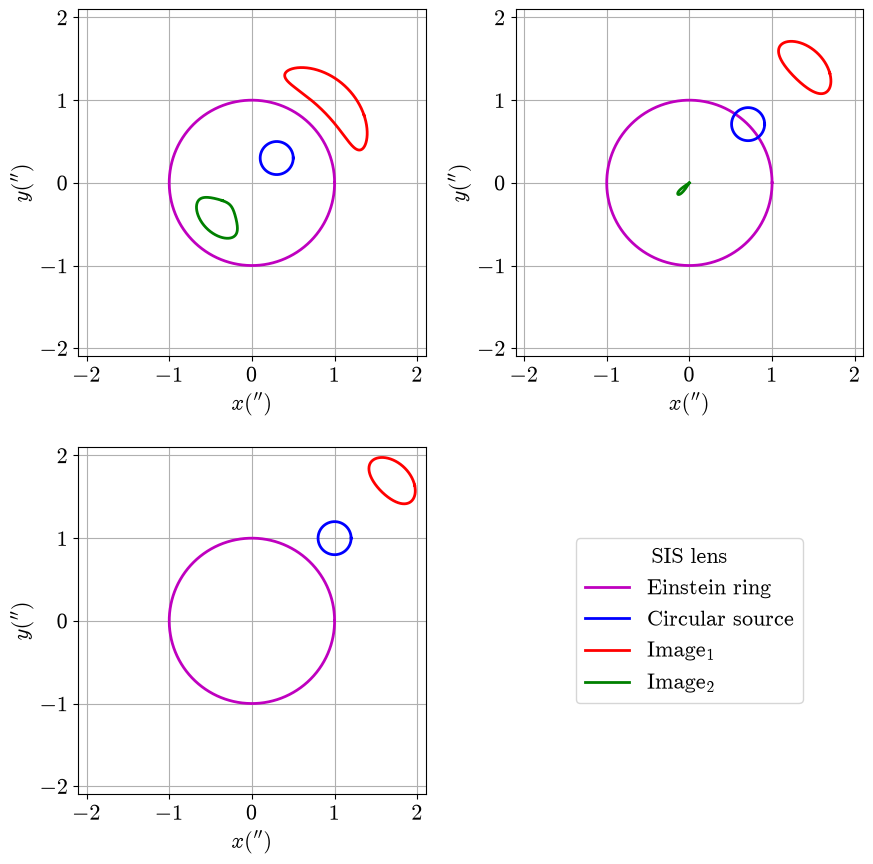

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True
})

# Einstein radius
re = 1.0

# Three positions of the source center and its radius
betacx = np.array([0.3, 0.71, 1.0])
betacy = np.array([0.3, 0.71, 1.0])
rs = 0.2

# Parametrizing variable
dphi = np.pi / 1000.0
phi = np.arange(dphi, 2.0 * np.pi + dphi, dphi)

# Einstein ring
thex = re * np.cos(phi) # x and y coordinates for the circle 
they = re * np.sin(phi)

# Create figure with 4 subplots (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(9, 9), subplot_kw={'aspect': 'equal'})

# Flatten the 2D axes matrix into a 1D array for easier iteration
axes = axes.flatten()

# Loop through all three positions of the source center
for i in range(3):
    ax = axes[i]

    # Source positions, current x and y from the source
    betax = betacx[i] + rs * np.cos(phi) 
    betay = betacy[i] + rs * np.sin(phi)
    beta = np.sqrt(betax**2 + betay**2)

    # The first image which exists always
    theta1 = beta + re
    theta1x = theta1 * betax / beta
    theta1y = theta1 * betay / beta

    # The second image which exists only if beta < re
    theta2 = beta - re
    theta2x = theta2 * betax / beta
    theta2y = theta2 * betay / beta

    # Plot the Einstein ring, source, and the always-present first image
    ax.plot(thex, they, 'm-', lw=2, label='Einstein ring')
    ax.plot(betax, betay, 'b-', lw=2, label='Circular source')
    ax.plot(theta1x, theta1y, 'r-', lw=2, label='Image$_{1}$')

    # Plot the second image only where beta < re
    if np.any(beta < re):
        ax.plot(theta2x[beta < re], theta2y[beta < re], 'g-', lw=2, label='Image$_{2}$')

    # Subplot configurations
    ax.grid(True)
    ax.set_xlim(-2.1, 2.1)
    ax.set_ylim(-2.1, 2.1)
    ax.set_xticks(np.arange(-2.0, 2.1, 1.0))
    ax.set_yticks(np.arange(-2.0, 2.1, 1.0))
    ax.tick_params(axis='both', which='major')
    ax.set_xlabel(r'$x(^{\prime\prime})$')
    ax.set_ylabel(r'$y(^{\prime\prime})$')

# Configure the fourth subplot which hosts the legend
ax_leg = axes[3]
ax_leg.axis('off')
handles, labels = axes[0].get_legend_handles_labels()
leg = ax_leg.legend(handles, labels, title='SIS lens', loc='center')

# Automatically adjust subplot alignment
plt.tight_layout()

# Save and show the figure
plt.savefig('sisl_circs.png', dpi=300, bbox_inches='tight')
plt.show()


Buscar que significa que quede dentro del ring o fuera.